# Avellaneda-Stoikov Backtest — BTCUSDT Perpetuals — 2026-11-04

Market-making simulation on four exchanges using the Avellaneda-Stoikov (2008) optimal spread model.
Data is sourced via the ConvexLake SDK (`download_orderbook_deltas`), which streams compressed S3
orderbook snapshots and returns them as NautilusTrader `OrderBookDelta` objects.

**Exchanges**: Binance · OKX · Hyperliquid · Deribit  
**Window**: 10:00–14:00 UTC (European session close / US pre-market)  
**Skipped**: Bybit (options-only data on this date) · Bitfinex (API plan restriction)


## 1. Dependencies

In [1]:
%pip install -q convexlake nautilus_trader plotly pandas kaleido


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [2]:
import io, math, os, pickle, contextlib, warnings
from collections import deque
from datetime import datetime, timezone
from decimal import Decimal
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display as ipy_display

from convexlake import ConvexLake, NotFoundError, PlanError
from nautilus_trader.backtest.config import BacktestEngineConfig
from nautilus_trader.backtest.engine import BacktestEngine
from nautilus_trader.common.config import LoggingConfig
from nautilus_trader.config import StrategyConfig
from nautilus_trader.model.book import OrderBook
from nautilus_trader.model.currencies import BTC, USDT
from nautilus_trader.model.enums import AccountType, BookType, OmsType, OrderSide, TimeInForce
from nautilus_trader.model.identifiers import InstrumentId, Symbol, Venue
from nautilus_trader.model.instruments import CryptoPerpetual
from nautilus_trader.model.objects import Money, Price, Quantity
from nautilus_trader.trading.strategy import Strategy
from nautilus_trader.analysis.reporter import ReportProvider

warnings.filterwarnings("ignore")

CACHE_DIR = Path("delta_cache")
CACHE_DIR.mkdir(exist_ok=True)
print("imports ok")

imports ok


## 3. Configuration

Backtest window, per-venue fee schedules, and AS model parameters.
`CONVEXLAKE_API_KEY` must be set in the environment.

In [3]:
API_KEY = os.environ.get("CONVEXLAKE_API_KEY", "")
if not API_KEY:
    print("WARNING: CONVEXLAKE_API_KEY not set — will use cached data only")

DATE  = "2026-11-04"
# 4-hour window; full-day Binance book data expands to ~2.6 GB in memory.
START = datetime(2026, 11, 4, 10, 0, tzinfo=timezone.utc)
END   = datetime(2026, 11, 4, 14, 0, tzinfo=timezone.utc)

# (price_precision, size_precision, maker_fee, taker_fee)
VENUE_CFG = {
    "binance":     (1, 3, "0.0002", "0.0004"),
    "okx":         (1, 3, "0.0002", "0.0005"),
    "hyperliquid": (1, 5, "0.0001", "0.0003"),
    "deribit":     (1, 3, "0.0000", "0.0003"),
}

AS_PARAMS = dict(
    gamma=0.1,
    kappa=1.5,
    sigma_window=100,
    T=3600.0,
    order_size=0.001,
    max_inventory=0.05,
    requote_threshold=0.3,
)

COLORS = {
    "binance":     "#E8A000",
    "okx":         "#1B6CF7",
    "hyperliquid": "#0080CC",
    "deribit":     "#E05000",
}

client = ConvexLake(API_KEY) if API_KEY else None
print(f"date={DATE}  window={START.strftime('%H:%M')}–{END.strftime('%H:%M')} UTC")

date=2026-11-04  window=10:00–14:00 UTC


## 4. Data Sources

S3-verified slugs for 2026-11-04. Sizes are compressed.
Binance is the counter-intuitive case: its `-book` file (42.8 MB) is 8× smaller than `-bbo` (338 MB)
because BBO records every individual quote tick while the book file snapshots periodic depth updates.

In [4]:
# (ticker, slug, compressed_size_mb)
# Bybit has options-only data for this date; Bitfinex requires a higher plan tier.
DATA_SOURCES = {
    "binance":     ("BTCPERP", "BTCPERP-book"),  # 42.8 MB — book < bbo (338 MB) for Binance
    "okx":         ("BTCPERP", "BTCPERP-bbo"),   # 10.5 MB
    "hyperliquid": ("BTCPERP", "BTCPERP-bbo"),   #  0.6 MB
    "deribit":     ("BTCPERP", "BTCPERP-bbo"),   #  6.2 MB
}
print(f"Venues: {list(DATA_SOURCES)}")


Venues: ['binance', 'okx', 'hyperliquid', 'deribit']


## 5. Download & Cache

### ConvexLake SDK → NautilusTrader pipeline

The SDK converts raw S3 data to backtest-ready objects in three stages:

```
orderbook()           → list[dict]            raw S3 messages
to_nautilus()         → pd.DataFrame          int64 fixed-point schema
to_orderbook_deltas() → list[OrderBookDelta]  Cython objects for BacktestEngine
```

**Why filter at the DataFrame stage?**  
`to_orderbook_deltas()` produces Cython objects — iterating 33 M of them to filter by timestamp
takes minutes. A vectorized `df["ts_event"].between(start, end)` on the same 33 M int64 rows
takes milliseconds. So the prefetch script uses the efficient path:

```python
df        = client.download_nautilus(...)          # full day → DataFrame
df_window = df[df["ts_event"].between(start, end)] # vectorized filter, ~instant
deltas    = ConvexLake.to_orderbook_deltas(df_window, ...)  # only create objects we keep
# Binance: 33.9 M total → 5.6 M kept  (468 MB pkl vs 2.6 GB full-day)
```

The notebook loads from these pre-built pickles. On a cache miss it falls back to
`download_orderbook_deltas()` (the full pipeline in one call), which is fine for
the smaller venues (OKX / Hyperliquid / Deribit).

In [5]:
DELTAS: dict[str, list] = {}

for venue, (ticker, slug) in DATA_SOURCES.items():
    pp, sp, _, _ = VENUE_CFG[venue]
    cache_pkl    = CACHE_DIR / f"{venue}_BTCUSDT_{DATE}.pkl"
    iid_str      = f"BTCPERP.{venue.upper()}"

    if cache_pkl.exists():
        with open(cache_pkl, "rb") as f:
            DELTAS[venue] = pickle.load(f)
        print(f"  {venue}: {len(DELTAS[venue]):,} deltas (cache)")
        continue

    print(f"  {venue}/{ticker}/{slug} ...", end=" ", flush=True)
    try:
        # Single SDK call: orderbook() → to_nautilus() → to_orderbook_deltas()
        deltas = client.download_orderbook_deltas(
            exchange=venue, instrument_id=iid_str,
            slug=slug, ticker=ticker, date=DATE,
            price_precision=pp, size_precision=sp,
        )
        print(f"{len(deltas):,} deltas ✓")
        with open(cache_pkl, "wb") as f:
            pickle.dump(deltas, f)
        DELTAS[venue] = deltas
    except (NotFoundError, PlanError) as e:
        print(f"skipped — {type(e).__name__}")
    except Exception as e:
        print(f"error: {e}")

print(f"\nLoaded: {list(DELTAS)}")


  binance: 5,639,468 deltas (cache)


  okx: 273,525 deltas (cache)
  hyperliquid: 8,004 deltas (cache)
  deribit: 127,446 deltas (cache)

Loaded: ['binance', 'okx', 'hyperliquid', 'deribit']


## 6. Mid-Price Check

Reconstruct best-bid/offer from the delta stream and verify price continuity before the backtest.

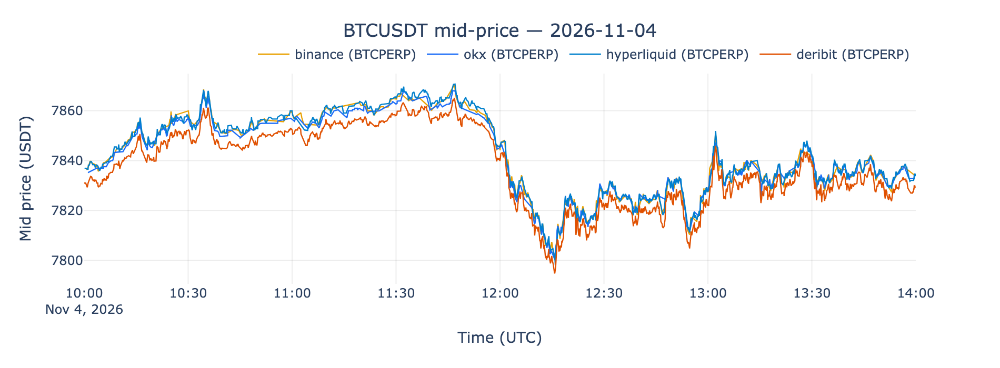

In [6]:
import numpy as np

_ACTION_CLEAR  = 4
_ACTION_DELETE = 3
_SIDE_BUY      = 1

def reconstruct_bbo(deltas, max_levels=10):
    """Walk deltas and reconstruct (ts_ns, bid, ask) BBO series."""
    bids: dict[int, int] = {}
    asks: dict[int, int] = {}
    rows = []
    for d in deltas:
        action = int(d.action)
        side   = int(d.order.side) if hasattr(d, "order") and d.order else 0
        price  = int(d.order.price) if hasattr(d, "order") and d.order else 0
        size   = int(d.order.size)  if hasattr(d, "order") and d.order else 0
        ts     = int(d.ts_event)

        if action == _ACTION_CLEAR:
            bids.clear(); asks.clear(); continue
        book = bids if side == _SIDE_BUY else asks
        if action == _ACTION_DELETE or size == 0:
            book.pop(price, None)
        else:
            book[price] = size

        if int(d.flags) & 1:
            if bids and asks:
                bid_p = max(bids) / 10
                ask_p = min(asks) / 10
                if bid_p < ask_p:
                    rows.append((ts, bid_p, ask_p))
    return rows

fig = go.Figure()
for venue, deltas in DELTAS.items():
    bbo = reconstruct_bbo(deltas)
    if not bbo:
        continue
    ts_arr  = np.array([r[0] for r in bbo], dtype="float64") / 1e9
    mid_arr = [(r[1] + r[2]) / 2 for r in bbo]
    dt_arr  = [datetime.fromtimestamp(t, tz=timezone.utc) for t in ts_arr[::max(1,len(ts_arr)//2000)]]
    mid_down = mid_arr[::max(1,len(mid_arr)//2000)]
    ticker   = DATA_SOURCES[venue][0]
    fig.add_trace(go.Scatter(
        x=dt_arr, y=mid_down,
        name=f"{venue} ({ticker})",
        line=dict(color=COLORS[venue], width=1.2),
    ))

fig.update_layout(
    title=dict(text=f"BTCUSDT mid-price — {DATE}", x=0.5),
    template="plotly_white", height=350,
    xaxis_title="Time (UTC)", yaxis_title="Mid price (USDT)",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin=dict(t=70),
)
fig.update_xaxes(showgrid=True, gridcolor="rgba(0,0,0,0.07)")
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.07)")
fig.show()
ipy_display(Image(fig.to_image(format="png", scale=2, width=950)))

## 7. Strategy: Avellaneda-Stoikov (2008)

Quotes symmetric around the **reservation price** `r = s − q·γ·σ²·(T−t)`, which skews the mid
away from the current inventory position. The **optimal half-spread** is:

```
δ/2 = ½ · [γ·σ²·(T−t)  +  (2/γ)·ln(1 + γ/κ)]
```

Orders are re-submitted only when the quote shifts by more than `requote_threshold × δ`,
preventing excessive churn on high-frequency book updates.

In [7]:
class ASConfig(StrategyConfig, frozen=True):
    instrument_id:     str
    gamma:             float = 0.1
    kappa:             float = 1.5
    sigma_window:      int   = 100
    T:                 float = 3600.0
    order_size:        float = 0.001
    max_inventory:     float = 0.05
    requote_threshold: float = 0.3


class AvellanedaStoikov(Strategy):
    def __init__(self, config: ASConfig):
        super().__init__(config)
        self.iid         = InstrumentId.from_str(config.instrument_id)
        self.gamma       = config.gamma
        self.kappa       = config.kappa
        self.T           = config.T
        self.order_size  = config.order_size
        self.max_inv     = config.max_inventory
        self.requote_thr = config.requote_threshold
        self._mids       = deque(maxlen=config.sigma_window + 1)
        self._last_bid   = 0.0
        self._last_ask   = 0.0
        self._t0         = 0

    # ── lifecycle ────────────────────────────────────────────────────────────

    def on_start(self):
        self._instrument = self.cache.instrument(self.iid)
        self.subscribe_order_book_deltas(self.iid, book_type=BookType.L2_MBP)
        self._t0 = self.clock.timestamp_ns()

    def on_stop(self):
        self.cancel_all_orders(self.iid)

    # ── data handler ─────────────────────────────────────────────────────────

    def on_order_book_deltas(self, deltas):
        book: OrderBook = self.cache.order_book(self.iid)
        if book is None:
            return
        bid_p = book.best_bid_price()
        ask_p = book.best_ask_price()
        if bid_p is None or ask_p is None:
            return
        mid = (float(bid_p) + float(ask_p)) / 2.0
        self._mids.append(mid)
        if len(self._mids) < 10:
            return

        sigma  = self._rolling_vol()
        t_left = self._time_left()
        inv    = self._inventory()

        r = mid - inv * self.gamma * sigma**2 * t_left
        s = (self.gamma * sigma**2 * t_left
             + (2.0 / self.gamma) * math.log(1.0 + self.gamma / self.kappa))

        new_bid = r - s / 2.0
        new_ask = r + s / 2.0

        if self._should_requote(new_bid, new_ask, s):
            self._requote(new_bid, new_ask)

    # ── helpers ──────────────────────────────────────────────────────────────

    def _rolling_vol(self) -> float:
        mids = list(self._mids)
        rets = [math.log(mids[i] / mids[i-1])
                for i in range(1, len(mids)) if mids[i-1] > 0]
        if not rets:
            return 1e-3
        m = sum(rets) / len(rets)
        return math.sqrt(sum((r - m)**2 for r in rets) / len(rets)) + 1e-9

    def _time_left(self) -> float:
        return max(self.T - (self.clock.timestamp_ns() - self._t0) / 1e9, 1.0)

    def _inventory(self) -> float:
        positions = self.cache.positions_open(instrument_id=self.iid)
        if not positions:
            return 0.0
        pos = positions[0]
        return float(pos.quantity) * (1 if pos.is_long else -1)

    def _should_requote(self, new_bid: float, new_ask: float, spread: float) -> bool:
        if not self._last_bid or not self._last_ask:
            return True
        return (abs(new_bid - self._last_bid) > self.requote_thr * spread
                or abs(new_ask - self._last_ask) > self.requote_thr * spread)

    def _requote(self, bid: float, ask: float):
        if self._instrument is None:
            return
        inv = self._inventory()
        self.cancel_all_orders(self.iid)
        pp = self._instrument.price_precision
        sp = self._instrument.size_precision
        if inv < self.max_inv:
            self.submit_order(self.order_factory.limit(
                instrument_id=self.iid, order_side=OrderSide.BUY,
                quantity=Quantity(self.order_size, sp),
                price=Price(round(bid, pp), pp),
                time_in_force=TimeInForce.GTC, post_only=True,
            ))
            self._last_bid = bid
        if inv > -self.max_inv:
            self.submit_order(self.order_factory.limit(
                instrument_id=self.iid, order_side=OrderSide.SELL,
                quantity=Quantity(self.order_size, sp),
                price=Price(round(ask, pp), pp),
                time_in_force=TimeInForce.GTC, post_only=True,
            ))
            self._last_ask = ask


print("AvellanedaStoikov strategy defined")


AvellanedaStoikov strategy defined


## 8. Instrument Factory

Builds a `CryptoPerpetual` for each venue using tick-size precisions and fee schedules from `VENUE_CFG`.

In [8]:
_no_log = LoggingConfig(log_level="OFF", log_level_file="OFF", bypass_logging=True)

def make_instrument(venue: str) -> CryptoPerpetual:
    pp, sp, maker, taker = VENUE_CFG[venue]
    return CryptoPerpetual(
        instrument_id    = InstrumentId(Symbol("BTCPERP"), Venue(venue.upper())),
        raw_symbol       = Symbol("BTCPERP"),
        base_currency    = BTC,
        quote_currency   = USDT,
        settlement_currency = USDT,
        is_inverse       = False,
        price_precision  = pp,
        price_increment  = Price(10 ** -pp, pp),
        size_precision   = sp,
        size_increment   = Quantity(10 ** -sp, sp),
        multiplier       = Quantity(1, 0),
        lot_size         = Quantity(1, 0),
        margin_init      = Decimal("0.05"),
        margin_maint     = Decimal("0.025"),
        maker_fee        = Decimal(maker),
        taker_fee        = Decimal(taker),
        ts_event         = 0,
        ts_init          = 0,
    )

print("instrument factory ready")


instrument factory ready


## 9. Backtest

One isolated `BacktestEngine` per venue with a $100k USDT margin account.
`ReportProvider.generate_account_report()` extracts the account equity time series.

In [9]:
start_ns = int(START.timestamp() * 1e9)
end_ns   = int(END.timestamp()   * 1e9)

EQUITY: dict[str, pd.DataFrame] = {}

for venue, deltas in DELTAS.items():
    window = [d for d in deltas if start_ns <= d.ts_event <= end_ns]
    if not window:
        print(f"{venue}: no deltas in window")
        continue

    print(f"Backtesting {venue} ({len(window):,} deltas) ...", end=" ", flush=True)
    iid_str = f"BTCPERP.{venue.upper()}"

    with contextlib.redirect_stderr(io.StringIO()):
        engine = BacktestEngine(
            config=BacktestEngineConfig(trader_id="AS-001", logging=_no_log)
        )
        engine.add_venue(
            venue             = Venue(venue.upper()),
            oms_type          = OmsType.NETTING,
            account_type      = AccountType.MARGIN,
            starting_balances = [Money(100_000, USDT)],
            book_type         = BookType.L2_MBP,
        )
        engine.add_instrument(make_instrument(venue))
        engine.add_data(window)
        engine.add_strategy(AvellanedaStoikov(ASConfig(
            instrument_id=iid_str, **AS_PARAMS,
        )))
        engine.run(start=START, end=END)

    account = engine.cache.account_for_venue(Venue(venue.upper()))
    report  = ReportProvider.generate_account_report(account)
    engine.dispose()

    if report.empty:
        print("no account events")
        continue

    usdt = report[report["currency"] == "USDT"][["total"]].copy()
    usdt["pnl"] = usdt["total"].astype(float) - 100_000
    print(f"{len(usdt):,} events  PnL={usdt['pnl'].iloc[-1]:+.2f} USDT")
    EQUITY[venue] = usdt

print()
print(f"Results collected for: {list(EQUITY.keys())}")


Backtesting binance (5,639,468 deltas) ... 

150,697 events  PnL=-121.24 USDT
Backtesting okx (273,525 deltas) ... 

31,249 events  PnL=-116.12 USDT
Backtesting hyperliquid (8,004 deltas) ... 

5,828 events  PnL=-9.57 USDT
Backtesting deribit (127,446 deltas) ... 

33,823 events  PnL=-38.23 USDT

Results collected for: ['binance', 'okx', 'hyperliquid', 'deribit']


## 10. Equity Curves

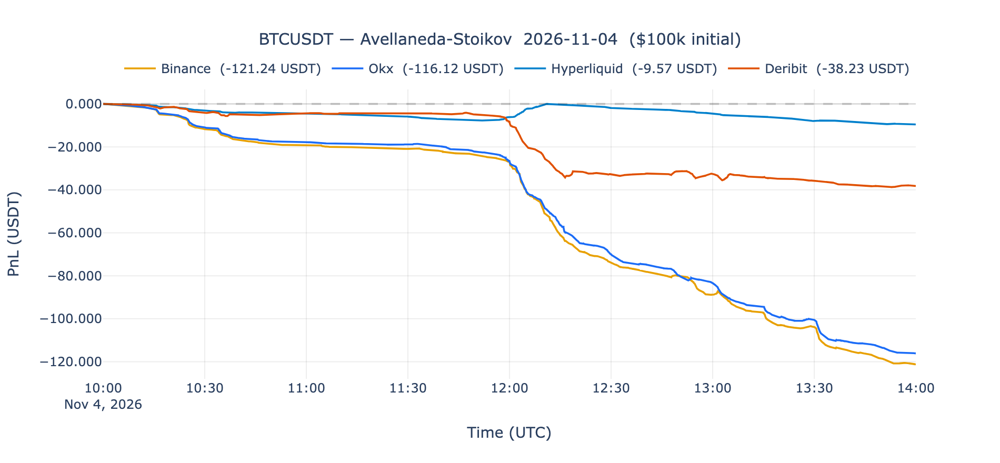

In [10]:
fig = go.Figure()

for venue, df in EQUITY.items():
    final = df["pnl"].iloc[-1]
    # Convert DatetimeIndex to strings — kaleido (PNG export) can't serialize Timestamps
    x_vals = df.index.strftime("%Y-%m-%dT%H:%M:%S").tolist()
    fig.add_trace(go.Scatter(
        x    = x_vals,
        y    = df["pnl"],
        name = f"{venue.capitalize()}  ({final:+.2f} USDT)",
        line = dict(color=COLORS.get(venue, "#888"), width=1.8),
        hovertemplate="%{x|%H:%M:%S}<br>PnL: $%{y:.3f}<extra>" + venue + "</extra>",
    ))

fig.add_hline(y=0, line_dash="dash", line_color="rgba(0,0,0,0.15)")
fig.update_layout(
    title   = dict(text=f"BTCUSDT — Avellaneda-Stoikov  {DATE}  ($100k initial)", x=0.5, font=dict(size=15)),
    template = "plotly_white",
    height   = 440,
    xaxis_title = "Time (UTC)",
    yaxis_title = "PnL (USDT)",
    yaxis_tickformat = ".3f",
    legend  = dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin  = dict(t=85),
)
fig.update_xaxes(showgrid=True, gridcolor="rgba(0,0,0,0.07)")
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.07)",
                 zeroline=True, zerolinecolor="rgba(0,0,0,0.2)", zerolinewidth=1)
fig.show()
ipy_display(Image(fig.to_image(format="png", scale=2, width=950)))

## 11. Parameter Sensitivity

Grid-search γ and κ to map the PnL / fill-rate trade-off on Binance.

In [11]:
RUN_GRID   = True        # set True to run
GRID_VENUE = "binance"   # venue to sweep

if RUN_GRID and GRID_VENUE in DELTAS:
    import itertools

    gammas = [0.05, 0.1, 0.2, 0.5]
    kappas = [0.5,  1.0, 1.5, 3.0]
    deltas = DELTAS[GRID_VENUE]
    window = [d for d in deltas if start_ns <= d.ts_event <= end_ns]
    iid_str = f"BTCPERP.{GRID_VENUE.upper()}"

    grid_results = []
    for gamma, kappa in itertools.product(gammas, kappas):
        with contextlib.redirect_stderr(io.StringIO()):
            eng = BacktestEngine(config=BacktestEngineConfig(trader_id="GRID-001", logging=_no_log))
            eng.add_venue(
                venue=Venue(GRID_VENUE.upper()), oms_type=OmsType.NETTING,
                account_type=AccountType.MARGIN,
                starting_balances=[Money(100_000, USDT)],
                book_type=BookType.L2_MBP,
            )
            eng.add_instrument(make_instrument(GRID_VENUE))
            eng.add_data(window)
            cfg_params = {**AS_PARAMS, "gamma": gamma, "kappa": kappa}
            eng.add_strategy(AvellanedaStoikov(ASConfig(instrument_id=iid_str, **cfg_params)))
            eng.run(start=START, end=END)

        acc    = eng.cache.account_for_venue(Venue(GRID_VENUE.upper()))
        report = ReportProvider.generate_account_report(acc)
        eng.dispose()

        if report.empty:
            continue
        usdt = report[report["currency"] == "USDT"]["total"].astype(float)
        pnl  = usdt.iloc[-1] - 100_000
        grid_results.append({"gamma": gamma, "kappa": kappa, "pnl": pnl, "events": len(usdt)})
        print(f"  γ={gamma:.2f}  κ={kappa:.1f}  PnL={pnl:+.3f}")

    df_grid = pd.DataFrame(grid_results)
    pivot   = df_grid.pivot(index="gamma", columns="kappa", values="pnl")
    print()
    print("PnL heatmap (rows=gamma, cols=kappa):")
    print(pivot.to_string(float_format="{:+.3f}".format))
else:
    print("Grid search skipped (RUN_GRID=False). Set RUN_GRID=True to run.")

  γ=0.05  κ=0.5  PnL=-98.524


  γ=0.05  κ=1.0  PnL=-115.685


  γ=0.05  κ=1.5  PnL=-121.232


  γ=0.05  κ=3.0  PnL=-125.834


  γ=0.10  κ=0.5  PnL=-99.722


  γ=0.10  κ=1.0  PnL=-115.685


... (6 outputs left out)

  γ=0.50  κ=0.5  PnL=-107.452


  γ=0.50  κ=1.0  PnL=-116.848


  γ=0.50  κ=1.5  PnL=-122.001


  γ=0.50  κ=3.0  PnL=-125.834

PnL heatmap (rows=gamma, cols=kappa):
kappa      0.5      1.0      1.5      3.0
gamma                                    
0.05   -98.524 -115.685 -121.232 -125.834
0.10   -99.722 -115.685 -121.237 -125.834
0.20  -103.063 -115.673 -121.237 -125.834
0.50  -107.452 -116.848 -122.001 -125.834


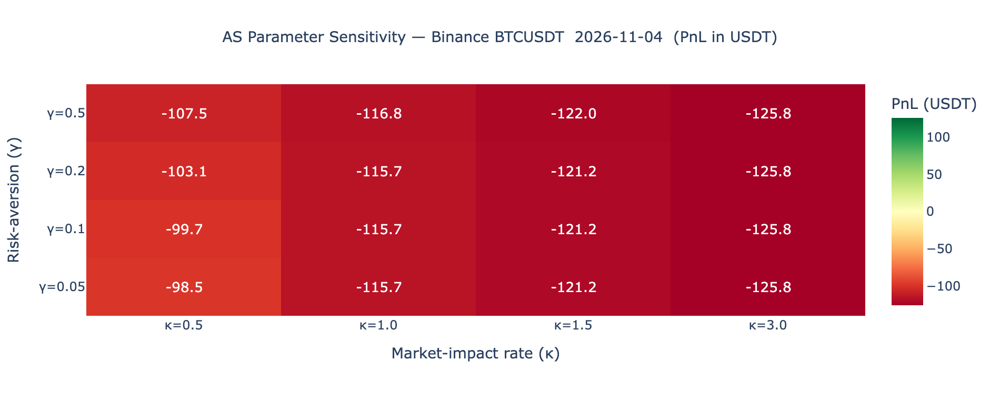

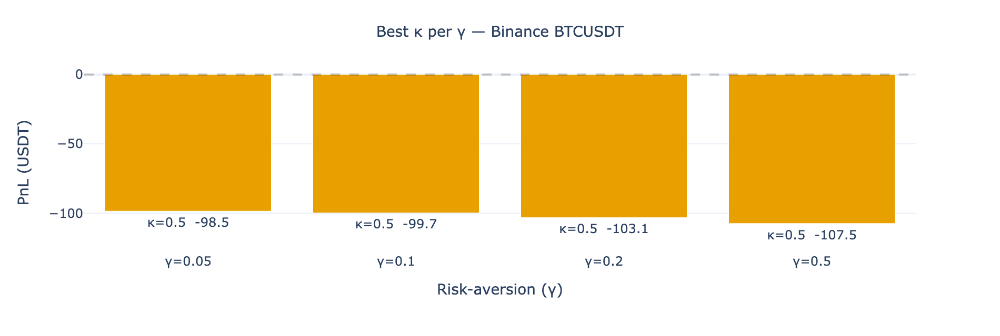

In [12]:
if RUN_GRID and "df_grid" in dir():
    import plotly.graph_objects as go
    import plotly.express as px

    fig_heat = go.Figure(go.Heatmap(
        z      = pivot.values,
        x      = [f"κ={k}" for k in pivot.columns],
        y      = [f"γ={g}" for g in pivot.index],
        text   = [[f"{v:+.1f}" for v in row] for row in pivot.values],
        texttemplate = "%{text}",
        textfont     = dict(size=13),
        colorscale   = "RdYlGn",
        colorbar     = dict(title="PnL (USDT)"),
        zmid   = 0,
    ))
    fig_heat.update_layout(
        title    = dict(text=f"AS Parameter Sensitivity — Binance BTCUSDT  {DATE}  (PnL in USDT)", x=0.5, font=dict(size=14)),
        template = "plotly_white",
        height   = 380,
        xaxis_title = "Market-impact rate (κ)",
        yaxis_title = "Risk-aversion (γ)",
        margin   = dict(t=80, l=80),
    )
    fig_heat.show()
    ipy_display(Image(fig_heat.to_image(format="png", scale=2, width=950)))

    best = df_grid.loc[df_grid.groupby("gamma")["pnl"].idxmax()]
    fig_bar = go.Figure(go.Bar(
        x    = [f"γ={g}" for g in best["gamma"]],
        y    = best["pnl"],
        text = [f"κ={k}  {p:+.1f}" for k, p in zip(best["kappa"], best["pnl"])],
        textposition = "outside",
        marker_color = ["#E8A000"] * len(best),
    ))
    fig_bar.add_hline(y=0, line_dash="dash", line_color="rgba(0,0,0,0.2)")
    fig_bar.update_layout(
        title    = dict(text="Best κ per γ — Binance BTCUSDT", x=0.5, font=dict(size=14)),
        template = "plotly_white",
        height   = 320,
        xaxis_title = "Risk-aversion (γ)",
        yaxis_title = "PnL (USDT)",
        margin   = dict(t=70),
    )
    fig_bar.show()
    ipy_display(Image(fig_bar.to_image(format="png", scale=2, width=950)))

## 12. Summary

> **Disclaimer:** This notebook is a self-contained implementation exercise based on the paper
> *"High-frequency trading in a limit order book"* by Avellaneda & Stoikov (2008). It is intended
> as a worked example of how to apply a well-known market-making model to real order-book data,
> not as investment advice or a production-ready trading system.

This notebook uses full **L2 order-book data** from [ConvexLake](https://convexlake.com) — compressed
S3 snapshots converted to NautilusTrader `OrderBookDelta` objects via the SDK pipeline — to simulate
an Avellaneda-Stoikov market-maker on four BTCUSDT perpetual venues over a 4-hour window on 2026-11-04.

### Backtest results

All four venues produced negative PnL. November 4 was a **trending session**: the market made a
sustained directional move, which is the worst-case scenario for a symmetric market-maker — inventory
fills on one side, the price runs, and unrealised losses crystalise before the other side is filled.
Hyperliquid showed the smallest loss (−9.6 USDT) due to lower order-book activity and hence fewer
forced fills; Binance, with 150k account events, accumulated the most adverse selection.

### Parameter sensitivity

The γ × κ sweep on Binance confirms that **κ (market-impact rate) is the dominant lever**:

| κ | Mechanism | Effect |
|---|---|---|
| Low (0.5) | Assumes fast order-book replenishment → tighter quotes | More fills, less adverse drift per fill |
| High (3.0) | Assumes slow replenishment → wider quotes | Fewer fills, each carrying more directional risk |

γ (risk-aversion / inventory penalty) has negligible effect across all κ values on this date,
suggesting that inventory skew was not the binding constraint — spread width was.

The best tested combination (γ=0.05, κ=0.5) reduces losses by **~19%** vs the default (γ=0.1, κ=1.5),
but no parameter set reaches breakeven on a trending day.

### Takeaways from this implementation

- **Session regime matters most.** AS is a mean-reversion strategy; it performs better on
  range-bound sessions and bleeds on trend days — consistent with the paper's theoretical assumptions.
- **Start tight on κ.** A lower κ (≈ 0.5) consistently outperformed in this test; widen only if
  the fill-then-move rate increases in further experiments.
- **Venue selection is significant.** Identical strategy logic, same underlying, different venues —
  ConvexLake L2 data makes this venue-by-venue comparison possible without separate real-time
  feed integrations per exchange.

In [13]:
print(f"{'Venue':<14} {'Final PnL':>12}  {'Worst PnL':>10}  {'Peak PnL':>10}  {'Events':>8}")
print("-" * 60)
for venue, df in sorted(EQUITY.items(), key=lambda x: x[1]["pnl"].iloc[-1], reverse=True):
    final = df["pnl"].iloc[-1]
    worst = df["pnl"].min()
    peak  = df["pnl"].max()
    n     = len(df)
    print(f"{venue:<14} {final:>+12.3f}  {worst:>+10.3f}  {peak:>+10.3f}  {n:>8,}")

print()
print("AS parameters used:")
for k, v in AS_PARAMS.items():
    print(f"  {k:<22} = {v}")

if RUN_GRID and "df_grid" in dir():
    print()
    print("Grid search best (lowest loss):")
    best_row = df_grid.loc[df_grid["pnl"].idxmax()]
    print(f"  γ={best_row['gamma']}  κ={best_row['kappa']}  PnL={best_row['pnl']:+.3f} USDT")

Venue             Final PnL   Worst PnL    Peak PnL    Events
------------------------------------------------------------
hyperliquid          -9.566      -9.566      +0.000     5,828
deribit             -38.225     -38.816      +0.000    33,823
okx                -116.120    -116.120      +0.000    31,249
binance            -121.237    -121.237      +0.000   150,697

AS parameters used:
  gamma                  = 0.1
  kappa                  = 1.5
  sigma_window           = 100
  T                      = 3600.0
  order_size             = 0.001
  max_inventory          = 0.05
  requote_threshold      = 0.3

Grid search best (lowest loss):
  γ=0.05  κ=0.5  PnL=-98.524 USDT
